# Session 6: k-means clustering and anomaly detection

**Course link:** Machine Learning Specialization, Course 3 Week 1 (k-means clustering: random initialisation, the cost function, choosing K by purpose; anomaly detection: a Gaussian per feature, p(x) < ε, tuning ε on a few known anomalies, transforming features to look more Gaussian).

**Questions:**
1. Do EU countries fall into natural groups by their economic conditions?
2. Does the data flag the country-years we already know are strange?

**Choices made before fitting anything:**
- **Clustering** uses one row per country: its average over 1995–2024 of four inputs: log of trade openness, debt, inflation capped at ±30 %, and GDP growth. The averages are z-scored across the 26 countries. K-means is my own code, as in the course lab, with 100 random starts, keeping the lowest cost, and checked against scikit-learn. K = 2 to 5.
- **Stability:** rerun with other random seeds, and with each country hidden in turn (the 25 others are clustered, then the hidden country joins its nearest group).
- **TFP growth after consolidations** by group: a description, not a cause.
- **Anomaly detection** uses one row per country-year with six features: ΔCAPB, GDP growth, inflation (not capped here, because Bulgaria 1997's extreme inflation is exactly what should be caught), debt, trade openness and one-year TFP growth. Clearly skewed features (inflation, debt, trade openness) are transformed to look more like a bell curve.
- **Known anomalies** (from CLAUDE.md's data watch-outs): Bulgaria 1997, Ireland 2010, Ireland 2011, Ireland 2015 and Greece 2010. The Gaussians are fitted on a training set of other country-years; ε is tuned on a cross-validation set that contains all five known anomalies. With only five labels there is no separate test set; this is said again where it matters.

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. Which countries do I expect to end up in the same group? Will any country be in a group of its own?
2. Which K do I expect the elbow plot to suggest?
3. Will the groups stay the same when a country is hidden, or with different random starts?
4. Which group will have the weakest TFP growth after consolidations?
5. Which of the known strange country-years (Bulgaria 1997, Ireland 2010–11 and 2015, Greece 2010) will be flagged? Which will be missed?
6. Which other country-years do I expect the anomaly detector to flag?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", None)
df = pd.read_csv(DATA_URL).sort_values(["country", "year"]).reset_index(drop=True)
COUNTRY, YEAR, DCAPB = "country", "year", "dcapb_main"
print(df.shape, df[COUNTRY].nunique(), "countries", df[YEAR].min(), "to", df[YEAR].max())

(780, 22) 26 countries 1995 to 2024


## 1. One row per country: averages of four inputs

**Course link:** k-means needs only the inputs, no target (unsupervised learning). Each country is described by its average conditions over 1995–2024. The averages are z-scored so that no input dominates the distances just because of its units.

In [3]:
FEATURES_K = ["log trade openness", "debt", "inflation (capped)", "GDP growth"]
d = df.copy()
d["log trade openness"] = np.log(d["trade_open"])
d["debt"] = d["debt_gdp"]
d["inflation (capped)"] = d["inflation"].clip(-30, 30)
d["GDP growth"] = d["gdp_growth"]
country_avg = d.groupby(COUNTRY)[FEATURES_K].mean()
country_avg.insert(1, "trade openness, % of GDP", np.exp(country_avg["log trade openness"]))
print(country_avg.round(1).sort_values("debt").to_string())

def zscore_fit(X):
    return X.mean(axis=0), X.std(axis=0)

X_raw = country_avg[FEATURES_K].to_numpy()
mu, sd = zscore_fit(X_raw)
X = (X_raw - mu) / sd
countries = country_avg.index.to_numpy()

             log trade openness  trade openness, % of GDP   debt  inflation (capped)  GDP growth
country                                                                                         
Estonia                     5.0                     143.2    9.5                 5.1         3.6
Luxembourg                  5.7                     298.3   15.7                 2.1         2.9
Romania                     4.2                      69.0   28.7                11.5         3.1
Lithuania                   4.8                     120.9   28.9                 3.8         4.1
Latvia                      4.7                     108.9   28.9                 4.6         3.4
Bulgaria                    4.6                     103.9   41.6                 6.3         2.4
Slovakia                    5.0                     150.6   45.0                 3.9         3.5
Sweden                      4.4                      84.2   46.0                 1.8         2.2
Denmark                     4.

## 2. K-means, my own code

**Course link:** the k-means lab. Repeat: (1) assign each country to its closest centroid; (2) move each centroid to the average of its countries. The **cost** (distortion) is the average squared distance from each country to its centroid. Different random starts can end in different local minima, so 100 starts are run and the lowest cost is kept.

In [4]:
def find_closest_centroids(X, centroids):
    dist = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    return dist.argmin(axis=1)

def compute_centroids(X, idx, K, old):
    return np.array([X[idx == k].mean(axis=0) if np.any(idx == k) else old[k] for k in range(K)])

def kmeans_cost(X, idx, centroids):
    return np.mean(((X - centroids[idx]) ** 2).sum(axis=1))

def run_kmeans(X, initial_centroids, max_iters=100):
    centroids = initial_centroids.copy()
    idx = find_closest_centroids(X, centroids)
    for _ in range(max_iters):
        centroids = compute_centroids(X, idx, len(centroids), centroids)
        new_idx = find_closest_centroids(X, centroids)
        if np.array_equal(new_idx, idx):
            break
        idx = new_idx
    return idx, centroids

def best_kmeans(X, K, n_starts=100, seed=0):
    # random starts: K distinct countries as the first centroids; keep the lowest cost
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_starts):
        idx, cents = run_kmeans(X, X[rng.permutation(len(X))[:K]])
        c = kmeans_cost(X, idx, cents)
        if best is None or c < best[0] - 1e-12:
            best = (c, idx, cents)
    return best

# Check against scikit-learn (its inertia is the total squared distance, so divide by the number of countries)
for K in range(2, 6):
    mine = best_kmeans(X, K)[0]
    sk = KMeans(n_clusters=K, n_init=100, random_state=0).fit(X).inertia_ / len(X)
    print(f"K = {K}: my cost {mine:.4f} | scikit-learn {sk:.4f}")

K = 2: my cost 2.3641 | scikit-learn 2.3641
K = 3: my cost 1.7778 | scikit-learn 1.7778
K = 4: my cost 1.3882 | scikit-learn 1.3882
K = 5: my cost 1.0403 | scikit-learn 1.0403


## 3. The elbow plot, and the groups for K = 2 to 5

**Course link:** *Choosing the number of clusters.* The cost always falls as K grows, so the "elbow" (where it stops falling quickly) is only a hint. The course's advice is to choose K by purpose: here, groups that are big enough to compare TFP growth after consolidations, and that make economic sense.

In the tables, each group's average inputs are in original units. "High" or "low" means more than half a standard deviation above or below the average country.

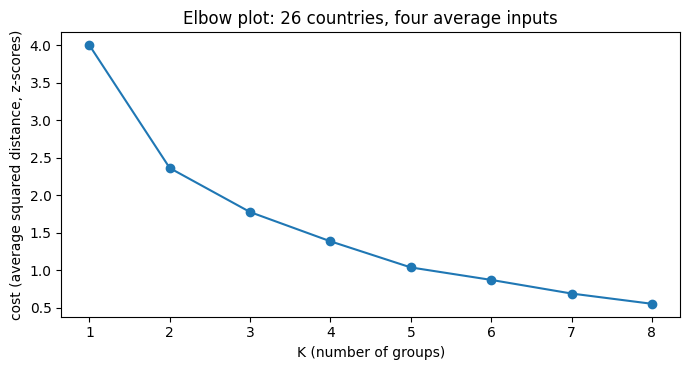

===== K = 2 (cost 2.364) =====
Group 1 (13): Austria, Belgium, Croatia, Denmark, Finland, France, Germany, Greece, Italy, Netherlands, Portugal, Spain, Sweden
   trade 84 % of GDP, debt 78 %, inflation 2.1 %, GDP growth 1.7 % -> less open to trade, high debt, low inflation, slow growth
Group 2 (13): Bulgaria, Cyprus, Estonia, Hungary, Ireland, Latvia, Lithuania, Luxembourg, Malta, Poland, Romania, Slovakia, Slovenia
   trade 142 % of GDP, debt 42 %, inflation 4.5 %, GDP growth 3.6 % -> very open to trade, low debt, high inflation, fast growth

===== K = 3 (cost 1.778) =====
Group 1 (13): Austria, Belgium, Croatia, Denmark, Finland, France, Germany, Greece, Italy, Netherlands, Portugal, Spain, Sweden
   trade 84 % of GDP, debt 78 %, inflation 2.1 %, GDP growth 1.7 % -> less open to trade, high debt, low inflation, slow growth
Group 2 (3): Bulgaria, Hungary, Romania
   trade 104 % of GDP, debt 47 %, inflation 8.2 %, GDP growth 2.6 % -> high inflation
Group 3 (10): Cyprus, Estonia, Irelan

In [5]:
Ks = range(1, 9)
costs = [best_kmeans(X, K)[0] for K in Ks]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(list(Ks), costs, "o-")
ax.set_xlabel("K (number of groups)"); ax.set_ylabel("cost (average squared distance, z-scores)")
ax.set_title("Elbow plot: 26 countries, four average inputs"); plt.tight_layout(); plt.show()

def describe(centroid_z):
    words = {"log trade openness": ("very open to trade", "less open to trade"), "debt": ("high debt", "low debt"),
             "inflation (capped)": ("high inflation", "low inflation"), "GDP growth": ("fast growth", "slow growth")}
    parts = [words[f][0] if z > 0.5 else words[f][1] for f, z in zip(FEATURES_K, centroid_z) if abs(z) > 0.5]
    return ", ".join(parts) if parts else "close to the average on everything"

def order_groups(idx):
    # name groups 1, 2, ... in order of their first country alphabetically, so tables are stable
    first = {}
    for i, g in enumerate(idx):
        first.setdefault(g, countries[i])
    rank = {g: r for r, g in enumerate(sorted(first, key=lambda g: first[g]))}
    return np.array([rank[g] for g in idx])

solutions = {}
for K in range(2, 6):
    cost, idx, cents = best_kmeans(X, K)
    idx = order_groups(idx)
    solutions[K] = idx
    print(f"===== K = {K} (cost {cost:.3f}) =====")
    for g in range(K):
        members = countries[idx == g]
        avg = country_avg.loc[members]
        z = X[idx == g].mean(axis=0)
        print(f"Group {g + 1} ({len(members)}): {', '.join(members)}")
        print(f"   trade {avg['trade openness, % of GDP'].mean():.0f} % of GDP, debt {avg['debt'].mean():.0f} %, "
              f"inflation {avg['inflation (capped)'].mean():.1f} %, GDP growth {avg['GDP growth'].mean():.1f} % -> {describe(z)}")
    print()

## 4. Are the groups stable?

Two checks, for each K:
- **Random seeds:** the whole 100-start search is repeated with 20 different seeds. A single random start is also shown, to see why many starts are needed.
- **Each country hidden in turn:** the other 25 countries are z-scored and clustered on their own; the hidden country then joins its nearest group.

To compare two groupings without worrying about group numbers, I use **pair agreement**: of all pairs of countries, the share where both groupings agree on "same group" or "different groups". 1.00 means identical groupings. (This is a simple version of what is called the Rand index; it is not in the course, so here is all it does.)

In [6]:
def pair_agreement(a, b):
    i, j = np.triu_indices(len(a), 1)
    return np.mean((a[i] == a[j]) == (b[i] == b[j]))

stab = {}
for K in range(2, 6):
    ref = solutions[K]
    seeds = [pair_agreement(ref, best_kmeans(X, K, seed=s)[1]) for s in range(1, 21)]
    singles = [pair_agreement(ref, best_kmeans(X, K, n_starts=1, seed=s)[1]) for s in range(1, 101)]
    hidden_agree, moved = [], []
    for h in range(len(X)):
        keep = np.arange(len(X)) != h
        m_h, s_h = zscore_fit(X_raw[keep])                         # scaling from the other 25 only
        Xk, xh = (X_raw[keep] - m_h) / s_h, (X_raw[h] - m_h) / s_h
        _, idx_k, cents_k = best_kmeans(Xk, K)
        full_new = np.empty(len(X), dtype=int)
        full_new[keep] = idx_k
        full_new[h] = find_closest_centroids(xh[None, :], cents_k)[0]
        hidden_agree.append(pair_agreement(ref, full_new))
        # does the hidden country end up with the same group-mates?
        mates_ref, mates_new = ref == ref[h], full_new == full_new[h]
        if not np.array_equal(mates_ref[keep], mates_new[keep]):
            moved.append(countries[h])
    stab[K] = {"20 other seeds (100 starts each): agreement, lowest": f"{min(seeds):.2f}",
               "a single random start: agreement, median (lowest)": f"{np.median(singles):.2f} ({min(singles):.2f})",
               "each country hidden in turn: agreement, median (lowest)": f"{np.median(hidden_agree):.2f} ({min(hidden_agree):.2f})",
               "rounds giving exactly the same grouping": f"{sum(a == 1.0 for a in hidden_agree)} of 26",
               "hidden countries that changed group-mates": ", ".join(moved) if moved else "none"}
pd.DataFrame(stab).T

,"20 other seeds (100 starts each): agreement, lowest","a single random start: agreement, median (lowest)","each country hidden in turn: agreement, median (lowest)",rounds giving exactly the same grouping,hidden countries that changed group-mates
2,1.00,1.00 (0.48),1.00 (0.92),23 of 26,"Belgium, Luxembourg, Romania"
3,1.00,0.84 (0.61),1.00 (0.87),16 of 26,"Belgium, Bulgaria, Croatia, Denmark, Hungary, Lithuania, Luxembourg, Romania, Slovakia, Sweden"
4,0.89,0.80 (0.66),0.96 (0.72),12 of 26,"Bulgaria, Denmark, Greece, Hungary, Italy, Lithuania, Netherlands, Romania, Slovakia, Slovenia"
5,0.86,0.80 (0.70),1.00 (0.86),15 of 26,"Belgium, Croatia, Cyprus, Denmark, Greece, Ireland, Italy, Luxembourg, Romania"


## 5. TFP growth after consolidations, by group (a description, not a cause)

For each group: the consolidation episodes (ΔCAPB ≥ 1.5 pp) and their TFP growth from t−1 to t+2, the same measure as in Sessions 1–5. The year-adjusted version subtracts the median growth of all countries in the same year. All country-years are shown for reference. The groups were formed from average conditions over the whole period, so a difference here says which kind of country had weaker growth after consolidating, not that the conditions or the consolidation caused it.

In [7]:
g = df.copy()
g["log_tfp"] = np.log(g["tfp"])
g["growth"] = 100 * (g.groupby(COUNTRY)["log_tfp"].shift(-2) - g.groupby(COUNTRY)["log_tfp"].shift(1))
g = g.dropna(subset=["growth", DCAPB])
g["year-adjusted growth"] = g["growth"] - g.groupby(YEAR)["growth"].transform("median")
episodes = g[g[DCAPB] >= 1.5]

for K in range(2, 6):
    group_of = dict(zip(countries, solutions[K] + 1))
    e, a = episodes.assign(group=episodes[COUNTRY].map(group_of)), g.assign(group=g[COUNTRY].map(group_of))
    table = pd.DataFrame({
        "countries": pd.Series(group_of).value_counts().sort_index(),
        "episodes": e.groupby("group").size(),
        "growth after episodes (%)": e.groupby("group")["growth"].mean(),
        "median": e.groupby("group")["growth"].median(),
        "year-adjusted (points)": e.groupby("group")["year-adjusted growth"].mean(),
        "all country-years (%)": a.groupby("group")["growth"].mean()}).rename_axis("group")
    print(f"K = {K}"); print(table.round(2).to_string()); print()

K = 2
       countries  episodes  growth after episodes (%)  median  year-adjusted (points)  all country-years (%)
group                                                                                                       
1             13        42                       1.44    2.28                   -1.57                   1.68
2             13        64                       3.87    4.22                    1.30                   5.55

K = 3
       countries  episodes  growth after episodes (%)  median  year-adjusted (points)  all country-years (%)
group                                                                                                       
1             13        42                       1.44    2.28                   -1.57                   1.68
2              3        17                       0.88    2.64                   -1.65                   5.50
3             10        47                       4.95    4.79                    2.36                   5.56

K = 4

## 6. Anomaly detection: histograms first

**Course link:** *Anomaly detection*, *Choosing what features to use.* The method assumes each feature looks roughly like a bell curve (Gaussian). Features with a long tail on one side are transformed first: inflation with a signed log (sign × log(1 + |x|), because inflation can be negative), trade openness with a log, and debt with a square root. (A log over-corrected debt: it left a long tail on the *low* side, from Estonia's very low debt; the square root looks closer to a bell. This was decided from the histograms alone.) ΔCAPB, GDP growth and one-year TFP growth are roughly symmetric and are left as they are: their long tails are exactly where anomalies should show up.

743 country-years with all six features


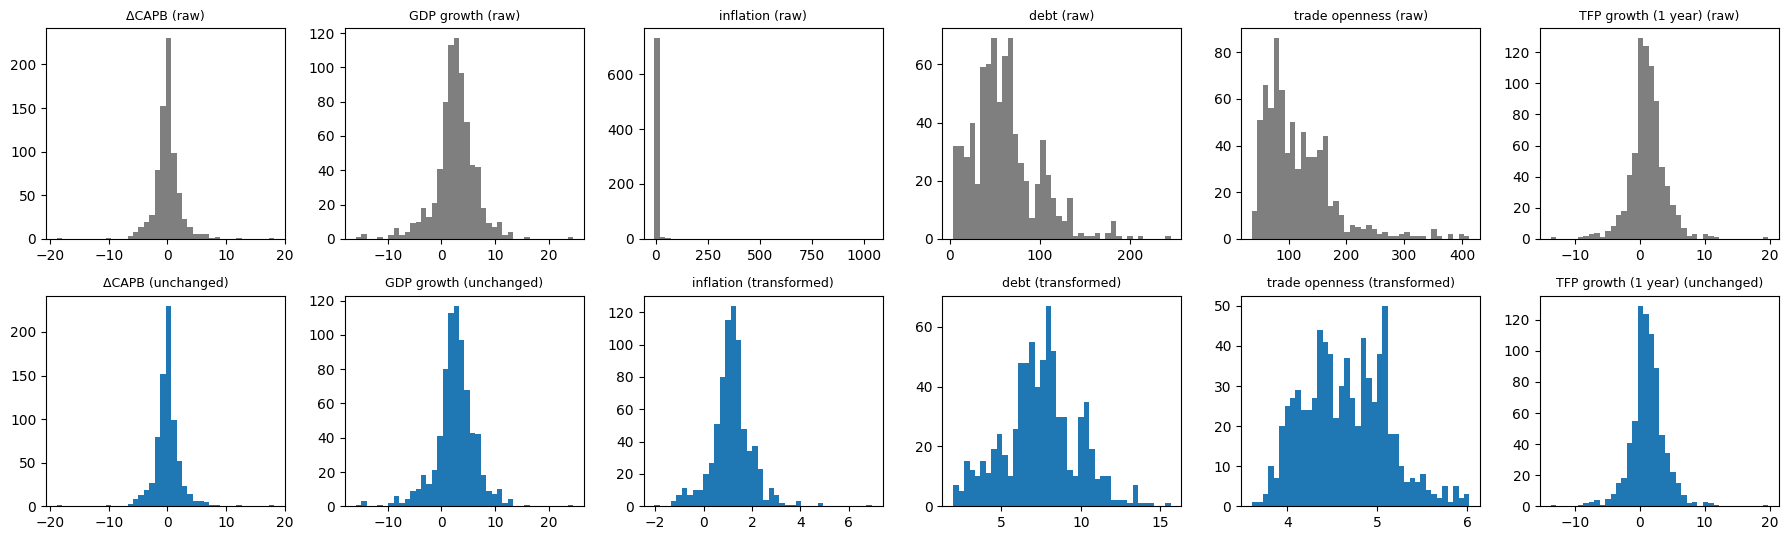

In [8]:
a = df.copy()
a["TFP growth (1 year)"] = 100 * a.groupby(COUNTRY)["tfp"].transform(lambda s: np.log(s).diff())
RAW = {"ΔCAPB": DCAPB, "GDP growth": "gdp_growth", "inflation": "inflation", "debt": "debt_gdp",
       "trade openness": "trade_open", "TFP growth (1 year)": "TFP growth (1 year)"}
a = a.rename(columns={v: k for k, v in RAW.items() if v != k}).dropna(subset=list(RAW))
TRANSFORM = {"inflation": lambda x: np.sign(x) * np.log1p(np.abs(x)), "debt": np.sqrt, "trade openness": np.log}
FEATURES_A = list(RAW)
A = a[[COUNTRY, YEAR]].copy()
for f in FEATURES_A:
    A[f] = TRANSFORM[f](a[f]) if f in TRANSFORM else a[f]
print(f"{len(A)} country-years with all six features")

fig, axes = plt.subplots(2, 6, figsize=(18, 5.5))
for j, f in enumerate(FEATURES_A):
    axes[0, j].hist(a[f], bins=40, color="tab:grey"); axes[0, j].set_title(f"{f} (raw)", fontsize=9)
    axes[1, j].hist(A[f], bins=40, color="tab:blue"); axes[1, j].set_title(f + (" (transformed)" if f in TRANSFORM else " (unchanged)"), fontsize=9)
plt.tight_layout(); plt.show()

## 7. Gaussians on training years, ε tuned on the known anomalies

- **Training set:** 60 % of the ordinary country-years, chosen at random. The mean and variance of each feature are estimated here.
- **Cross-validation set:** the other 40 % plus the five known anomalies. ε is chosen there by F1 (precision and recall for "anomaly").
- p(x) is the product of the six bell curves. It is worked with as log p(x) to avoid tiny numbers.
- With only five known anomalies there is no separate test set, and precision rests on very few cases.

In [9]:
KNOWN = [("Bulgaria", 1997), ("Ireland", 2010), ("Ireland", 2011), ("Ireland", 2015), ("Greece", 2010)]
A["known"] = [(c, y) in KNOWN for c, y in zip(A[COUNTRY], A[YEAR])]
normal = A[~A["known"]]
rng = np.random.default_rng(0)
train_idx = rng.choice(normal.index, size=int(0.6 * len(normal)), replace=False)
train = A.loc[train_idx]
cv = A.drop(index=train_idx)                       # the other ordinary years plus all known anomalies
print(f"training: {len(train)} country-years | cross-validation: {len(cv)} ({int(cv['known'].sum())} known anomalies)")

def fit_gaussians(X):
    return X.mean(axis=0), X.var(axis=0)

def log_p(X, mu, var):
    return (-0.5 * np.log(2 * np.pi * var) - (X - mu) ** 2 / (2 * var)).sum(axis=1)

mu_a, var_a = fit_gaussians(train[FEATURES_A].to_numpy())
cv_logp = log_p(cv[FEATURES_A].to_numpy(), mu_a, var_a)
y_cv = cv["known"].to_numpy()

def prf(flag, y):
    tp, fp, fn = int((flag & y).sum()), int((flag & ~y).sum()), int((~flag & y).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return precision, recall, (2 * precision * recall / (precision + recall) if precision + recall else 0.0), tp, fp

best = None
for eps in np.linspace(cv_logp.min(), cv_logp.max(), 2000):
    p_, r_, f_, tp, fp = prf(cv_logp < eps, y_cv)
    if best is None or f_ > best[1] + 1e-12:
        best = (eps, f_)
eps = best[0]
p_, r_, f_, tp, fp = prf(cv_logp < eps, y_cv)
print(f"chosen log ε = {eps:.2f}: precision {p_:.2f}, recall {r_:.2f}, F1 {f_:.2f} ({tp} known anomalies caught, {fp} other years flagged)")

print("\nOther choices of ε, on the cross-validation set:")
rows = []
for share in [0.01, 0.02, 0.05, 0.10]:
    e = np.quantile(cv_logp, share)
    pp, rr, ff, tp_, fp_ = prf(cv_logp <= e, y_cv)
    rows.append({"flag the lowest": f"{share:.0%}", "flagged": tp_ + fp_, "known caught": f"{tp_} of 5", "precision": round(pp, 2), "recall": round(rr, 2), "F1": round(ff, 2)})
print(pd.DataFrame(rows).to_string(index=False))

print("\nThe five known anomalies: rank among all cross-validation years (1 = most unusual)")
cv_rank = pd.Series(cv_logp, index=cv.index).rank()
for c, y in KNOWN:
    i = cv.index[(cv[COUNTRY] == c) & (cv[YEAR] == y)][0]
    print(f"   {c} {y}: log p = {cv_logp[cv.index.get_loc(i)]:.1f}, rank {int(cv_rank[i])} of {len(cv)}"
          f"{'  (flagged)' if cv_logp[cv.index.get_loc(i)] < eps else '  (missed)'}")

training: 442 country-years | cross-validation: 301 (5 known anomalies)
chosen log ε = -48.68: precision 1.00, recall 0.80, F1 0.89 (4 known anomalies caught, 0 other years flagged)

Other choices of ε, on the cross-validation set:
flag the lowest  flagged known caught  precision  recall   F1
             1%        4       4 of 5       1.00     0.8 0.89
             2%        7       4 of 5       0.57     0.8 0.67
             5%       16       5 of 5       0.31     1.0 0.48
            10%       31       5 of 5       0.16     1.0 0.28

The five known anomalies: rank among all cross-validation years (1 = most unusual)
   Bulgaria 1997: log p = -65.4, rank 1 of 301  (flagged)
   Ireland 2010: log p = -54.3, rank 3 of 301  (flagged)
   Ireland 2011: log p = -48.7, rank 4 of 301  (flagged)
   Ireland 2015: log p = -54.4, rank 2 of 301  (flagged)
   Greece 2010: log p = -21.5, rank 10 of 301  (missed)


## 8. What else does it flag?

The same Gaussians and ε, applied to every country-year (training years included). For each year, the feature furthest from normal (in standard deviations, after the transformation) shows *why* it is unusual. Then: what happens if ε is loosened to catch all five known anomalies, and which unlabelled years come closest to being flagged.

In [10]:
A["log p"] = log_p(A[FEATURES_A].to_numpy(), mu_a, var_a)
Z = (A[FEATURES_A] - mu_a) / np.sqrt(var_a)
A["main reason"] = [f"{Z.columns[k]} ({Z.iloc[i, k]:+.1f} sd)" for i, k in enumerate(np.abs(Z.to_numpy()).argmax(axis=1))]
flagged = A[A["log p"] < eps].sort_values("log p")
print(f"Flagged: {len(flagged)} of {len(A)} country-years ({len(flagged) / len(A):.1%}), "
      f"including {int(flagged['known'].sum())} of the 5 known anomalies")
show = flagged.merge(a[[COUNTRY, YEAR] + FEATURES_A], on=[COUNTRY, YEAR], suffixes=("", " raw"))
cols = [COUNTRY, YEAR, "log p", "main reason"] + [f + " raw" for f in FEATURES_A]
if (~show["known"]).any():
    print("\nFlagged years I did not label as known:")
    print(show[~show["known"]][cols].round(1).to_string(index=False))

# Loosen ε just enough to catch every known anomaly, and see what else comes with it
eps_all = A.loc[A["known"], "log p"].max() + 1e-9
loose = A[A["log p"] < eps_all]
print(f"\nWith ε loosened to catch all 5 known anomalies (log ε = {eps_all:.1f}): {len(loose)} country-years flagged "
      f"({len(loose) / len(A):.1%}), so precision would be {5 / len(loose):.2f} on the whole panel")

# The most unusual country-years I did not label, flagged or not
top = A[~A["known"]].sort_values("log p").head(15).merge(a[[COUNTRY, YEAR] + FEATURES_A], on=[COUNTRY, YEAR], suffixes=("", " raw"))
print("\nThe 15 most unusual country-years I did not label (most unusual first):")
print(top[cols].round(1).to_string(index=False))
print("\nAmong the 30 most unusual unlabelled years, per country:",
      A[~A["known"]].sort_values("log p").head(30).groupby(COUNTRY).size().sort_values(ascending=False).head(8).to_dict())

Flagged: 4 of 743 country-years (0.5%), including 4 of the 5 known anomalies

With ε loosened to catch all 5 known anomalies (log ε = -21.5): 19 country-years flagged (2.6%), so precision would be 0.26 on the whole panel

The 15 most unusual country-years I did not label (most unusual first):
  country  year  log p                   main reason  ΔCAPB raw  GDP growth raw  inflation raw  debt raw  trade openness raw  TFP growth (1 year) raw
  Estonia  2009  -31.8          GDP growth (-4.6 sd)        6.7           -14.5           -1.1       8.0               116.8                     -4.8
   Cyprus  2013  -31.2               ΔCAPB (+5.8 sd)       12.0            -6.8           -0.2     108.3               120.9                     -1.8
   Greece  2011  -28.5 TFP growth (1 year) (-3.5 sd)        6.1            -9.9            2.9     175.1                56.3                     -7.9
Lithuania  2009  -27.9          GDP growth (-4.7 sd)        1.2           -14.9            4.4      27.9  

# Learning log, Session 6 (12 Nov 2026)

**Course:** Machine Learning Specialization, Course 3 Week 1 (k-means clustering: random initialisation, cost, choosing K by purpose; anomaly detection: a Gaussian per feature, p(x) < ε, tuning ε on a few known anomalies, transforming features to look more Gaussian)

**Questions:** do EU countries fall into natural groups? Does the data flag the country-years we already know are strange?

**Setup, decided before fitting:**
- **Clustering:** one row per country, its 1995–2024 average of log trade openness, debt, inflation capped at ±30 % and GDP growth, z-scored across the 26 countries. My own k-means (as in the course lab), 100 random starts, lowest cost kept; K = 2 to 5.
- **Anomaly detection:** one row per country-year (743 with all six features): ΔCAPB, GDP growth, inflation (uncapped), debt, trade openness and one-year TFP growth. Skewed features transformed: inflation with a signed log, trade openness with a log, debt with a square root (a log over-corrected it, leaving a long low tail from Estonia; decided from the histograms only). A Gaussian per feature on 60 % of the ordinary country-years; ε tuned by F1 on the other 40 % plus the five known anomalies from CLAUDE.md (Bulgaria 1997, Ireland 2010, 2011 and 2015, Greece 2010). No separate test set: five labels are too few.

**Checks**
- My k-means reaches exactly scikit-learn's lowest cost for every K (K = 2: 2.3641; 3: 1.7778; 4: 1.3882; 5: 1.0403).
- The notebook runs in about 10 seconds.

**The groups, in plain words**
- **Elbow plot:** the cost falls from 4.00 (K = 1) to 2.36, 1.78, 1.39 and 1.04 (K = 5). The only clear bend is at K = 2; after that it falls steadily. As the course says, the elbow is only a hint.
- **K = 2: old core vs catching-up and small open economies.**
  - Group 1 (13): Austria, Belgium, Croatia, Denmark, Finland, France, Germany, Greece, Italy, Netherlands, Portugal, Spain, Sweden. Less open to trade (84 % of GDP), higher debt (78 %), low inflation (2.1 %), slow growth (1.7 %).
  - Group 2 (13): Bulgaria, Cyprus, Estonia, Hungary, Ireland, Latvia, Lithuania, Luxembourg, Malta, Poland, Romania, Slovakia, Slovenia. Very open (142 %), low debt (42 %), higher inflation (4.5 %), fast growth (3.6 %).
- **K = 3:** the high-inflation transition economies split off: Bulgaria, Hungary, Romania (inflation 8.2 %).
- **K = 4:** Greece and Italy also form their own group: debt 132 %, growth 1.0 %, the least open (56 %).
- **K = 5:** the catching-up group splits into the very open small economies (Cyprus, Ireland, Luxembourg, Malta: trade 201 % of GDP, growth 4.3 %) and Central and Eastern Europe (Bulgaria, Estonia, Hungary, Latvia, Lithuania, Poland, Slovakia, Slovenia), with Romania alone (inflation 11.5 %).
- Croatia sits with the old core in every K, despite joining the EU in 2013: its averages (trade 84 %, debt 53 %, growth 2.6 %) are closer to that group.

**Are the groups stable?**

| | K = 2 | K = 3 | K = 4 | K = 5 |
|---|---|---|---|---|
| 20 other seeds (100 starts each): lowest pair agreement | 1.00 | 1.00 | 0.89 | 0.86 |
| A single random start: median (lowest) | 1.00 (0.48) | 0.84 (0.61) | 0.80 (0.66) | 0.80 (0.70) |
| Each country hidden in turn: median (lowest) | 1.00 (0.92) | 1.00 (0.87) | 0.96 (0.72) | 1.00 (0.86) |
| Rounds giving exactly the same grouping | 23 of 26 | 16 of 26 | 12 of 26 | 15 of 26 |

- **K = 2 is the stable grouping.** Every seed finds it, and hiding any one country changes it only for Belgium, Luxembourg or Romania, the countries between the two groups.
- **From K = 4, the answer depends on the random seed** even with 100 starts each (pair agreement 0.89 and 0.86): there are several almost equally good groupings. One random start alone can be far off (pair agreement as low as 0.48 for K = 2), which is why the course uses many starts.
- **Choosing K by purpose:** for comparing growth after consolidations, K = 2 is the honest choice (stable, 42 and 64 episodes). K = 3 and 4 add interpretable but small groups (3 and 2 countries) that are less stable.

**TFP growth after consolidations, by group (a description, not a cause)**

| | Episodes | Growth after episodes (t−1 to t+2) | Median | Year-adjusted | All country-years |
|---|---|---|---|---|---|
| K = 2, old core | 42 | 1.44 % | 2.28 % | −1.57 | 1.68 % |
| K = 2, catching-up and small open | 64 | 3.87 % | 4.22 % | +1.30 | 5.55 % |
| K = 4, Bulgaria, Hungary, Romania | 17 | 0.88 % | 2.64 % | −1.65 | 5.50 % |
| K = 4, Greece and Italy | 10 | −2.53 % | 0.01 % | −4.82 | 0.65 % |

- After consolidations, growth is weaker in the old core (1.44 %) than in the catching-up group (3.87 %), but that mostly reflects their normal growth (1.68 % vs 5.55 % over all years). Compared with their own normal, the catching-up group's growth falls more after consolidations (−1.7 points vs −0.2).
- The weakest: Greece and Italy (−2.53 % after their 10 episodes, against 0.65 % normally) and Bulgaria, Hungary and Romania (0.88 % vs 5.50 %). Small groups, few episodes, and crisis-era timing for many of them, so this describes where growth was weak after consolidating, not why.

**Anomaly detection: does it flag the known strange years?**
- At the ε chosen by F1 (log ε = −48.7), it flags **4 of the 5 known anomalies and nothing else** in the cross-validation set: precision 1.00, recall 0.80.
- **Caught:**
  - Bulgaria 1997 (inflation 1,040 %; most unusual of 301)
  - Ireland 2015 (GDP +24.6 %, TFP +19.8 %; second)
  - Ireland 2010 (ΔCAPB −18.8; third)
  - Ireland 2011 (ΔCAPB +18.2; fourth)
- **Missed: Greece 2010** (10th of 301). It is unusual as a *combination* (ΔCAPB +7.4, GDP −5.7 %, debt 148 %), but not extreme on any single feature, and a Gaussian per feature cannot see combinations. The course's fix is to add a feature that combines them (for example a ratio or product), decided before looking.
- **Precision and recall trade-off** on the cross-validation set: flagging the lowest 1 % catches 4 of 5 with precision 1.00; 5 % catches all 5 with precision 0.31; 10 % catches all 5 with precision 0.16. Loosening ε on the whole panel just enough to catch Greece 2010 flags 19 country-years (2.6 %), a precision of 0.26.

**The most unusual years I had not labelled, grouped by cause**
- **The 2009 Baltic crash:** Estonia 2009 (GDP −14.5 %), Lithuania 2009 (−14.9 %), Latvia 2009 (−16.0 %). Real events, not data errors.
- **Transition-era inflation:** Romania 1997 (134 %), Bulgaria 1996 (113 %).
- **The Greek crisis:** Greece 2011 (TFP −7.9 %), 2013 (ΔCAPB −5.7), 2014 (ΔCAPB +8.4), 2020 (GDP −9.2 %, debt 209 %). Greece has 6 of the 30 most unusual unlabelled years.
- **Large budget swings:** Cyprus 2013 (ΔCAPB +12.0, already in CLAUDE.md's watch-outs) and Lithuania 1997 (ΔCAPB −9.6).
- **Possible data quirks worth checking:** one-year TFP jumps of +11.0 % in Ireland 2020 and +10.9 % in 2021 (likely the same multinational accounting as 2015), +12.2 % in Romania 2002 and +10.5 % in Estonia 1997.

**Checking the new flags against the source (added 12 Nov 2026)**
- The panel's TFP matches the AMECO series (ZVGDF) exactly in the thesis's raw files, so none of these jumps comes from processing. Splitting GDP growth into output per worker and employment shows what drives each:

| | TFP growth | Output per worker | GDP growth | Implied employment change | Verdict |
|---|---|---|---|---|---|
| Ireland 2020 | +11.0 % | +9.4 % | +7.2 % | −2.3 % | multinational accounting |
| Ireland 2021 | +10.9 % | +8.7 % | +16.3 % | +7.5 % | multinational accounting |
| Romania 2002 | +12.2 % | +16.3 % | +5.7 % | −10.6 % | most likely an employment-series break |
| Estonia 1997 | +10.5 % | +11.8 % | +12.3 % | +0.5 % | real catch-up growth |

- **Ireland 2020–21:** the same problem as 2015. Irish GDP reflects multinationals' accounts (intellectual property, contract manufacturing, pharma exports during COVID), not domestic productivity; GDP grew 7 % in 2020 when most EU economies shrank. Smaller jumps in 2014 (+6.3 %) and 2017 (+5.5 %) follow the same pattern.
- **Romania 2002:** GDP grew a normal 5.7 %, but employment would have had to fall 10.6 % in one year for TFP to jump 12 %. That fits a statistical revision of the employment figures (Romania's 2002 census), not a real fall; not yet confirmed against Eurostat's notes.
- **Estonia 1997:** GDP really grew about 12 % with employment flat: genuine fast catch-up growth, not a data problem.
- Both artefacts are now in CLAUDE.md's data watch-outs. They feed into the TFP growth target for Ireland's 2018–2021 windows and Romania's 2000–2002 windows.

**Quick check (12 Nov 2026): the Session 5B threshold without the flagged windows, and the K = 2 groups against their normal growth**

*1. ΔCAPB bands and the stump cut* (Session 5B sample of 669 country-years; average TFP growth, t−1 to t+2; dropping Ireland's target windows from 2013 on and Romania 2000–2002, 13 country-years, then Greece as well). No earlier notebook was changed.

| ΔCAPB band (pp) | < −1.5 | −1.5 to 0 | 0 to 1.5 | 1.5 to 3 | 3 to 4.5 | > 4.5 |
|---|---|---|---|---|---|---|
| All (Session 5B) | 3.78 % (120) | 3.56 % (247) | 3.78 % (209) | 3.57 % (54) | 2.09 % (21) | 0.16 % (18) |
| Without flagged windows | 3.56 % (118) | 3.17 % (242) | 3.73 % (206) | 2.78 % (51) | 2.09 % (21) | 0.16 % (18) |
| Without flagged windows and Greece | 3.76 % (107) | 3.17 % (236) | 3.73 % (203) | 2.77 % (50) | 1.95 % (20) | 2.59 % (14) |

| Stump (best single ΔCAPB cut) | Original: cut, below vs above | Gap | Placebo: shuffles as large | Year-adjusted: cut, gap | Placebo |
|---|---|---|---|---|---|
| All (Session 5B) | 3.45 pp: +3.69 % vs +0.28 % | 3.40 | 1.6 % | 3.45 pp, 2.78 | 2.6 % |
| Without flagged windows | 3.45 pp: +3.41 % vs +0.28 % | 3.13 | 0.4 % | 3.45 pp, 2.55 | 1.0 % |
| Without flagged windows and Greece | **1.85 pp**: +3.52 % vs +2.04 % | 1.47 | **18.2 %** | **0.75 pp**, 0.94 | **25.0 %** |

- **The flagged windows do not matter:** without Ireland 2013 onwards and Romania 2000–2002, the bands above 3 pp and the 3.45 pp cut are unchanged, and the placebo is even clearer (0.4 % and 1.0 %).
- **Greece does:** without it, the stump's best cut moves to 1.85 pp (original) and 0.75 pp (year-adjusted), the gap shrinks to 1.47 and 0.94 points, and the placebo no longer stands out (18 % and 25 % of shuffles do as well). The top band rises from 0.16 % to 2.59 %, because Greece 2010 and 2011 (−16.9 % and −16.5 %) are in it.
- At a fixed 3.45 pp cut, growth above it is still lower without Greece (mean 1.48 % vs 3.45 %, median 0.72 % vs 3.03 %, year-adjusted −0.48 vs +0.71), so large consolidations were still followed by weaker growth. But without Greece the bands look more like a general step down for all consolidations (2–2.8 % from 1.5 pp up, against 3.2–3.8 % for other years) than a sharp drop above about 3.5 pp.
- **This corrects Session 5B:** its robustness check measured the gap at a fixed 3.45 pp cut and found it held without Greece, but did not let the cut move. Letting it move shows that the 3.45 pp threshold, and its placebo pass, rest on Greece's crisis years.

*2. Session 6's K = 2 groups: growth after consolidations minus each group's normal growth* (Session 6 sample; "normal" = average over all country-years of the group; year-adjusted = minus the median across countries in the same year).

| | Episodes | After episodes | Normal | Difference | Year-adjusted: after | Normal | Difference |
|---|---|---|---|---|---|---|---|
| Catching-up and small open | 64 | 3.87 % | 5.55 % | **−1.68** | +1.30 | +2.70 | **−1.41** |
| Older core | 42 | 1.44 % | 1.68 % | **−0.24** | −1.57 | −1.15 | **−0.42** |
| Catching-up, without flagged windows | 61 | 3.22 % | 5.11 % | −1.89 | +0.66 | +2.28 | −1.62 |

- Compared with its own normal growth, the catching-up group's growth falls much more after consolidations (−1.7 points, −1.4 year-adjusted) than the older core's (−0.2, −0.4 year-adjusted). Dropping the flagged Irish and Romanian windows makes the catching-up gap slightly larger (−1.9, −1.6). The older core has no flagged windows.
- A description, not a cause: the catching-up economies grow fast normally, so a pause after consolidating shows up as a larger gap, and their consolidations cluster in crisis years.

**Main lessons**
- K-means always finds groups; whether they mean anything is shown by stability. Here K = 2 is solid, and from K = 4 the groups depend on the random start.
- Choosing K by purpose matters more than the elbow, which had no clear bend after K = 2.
- A Gaussian per feature catches years that are extreme on one feature (Bulgaria 1997, Ireland), but misses years that are unusual only as a combination (Greece 2010).
- With five labelled anomalies, precision and recall rest on very few cases; ε is a judgement call as much as a calculation.
- Anomaly detection is a useful data check: it confirmed the known quirks and found two new ones that the source data confirms (Ireland 2020–21, Romania 2002), plus one that turned out to be real (Estonia 1997).
- Clustering and anomaly detection describe the data; they say nothing about whether consolidations cause weaker growth.
- A robustness check should let the result move, not only test it at a fixed value: the 3.45 pp cut held at a fixed cut without Greece, but the best cut moved away once it could.

**Next:** Course 3 Week 2 (recommender systems).